In [5]:
import pandas as pd

In [6]:
df = pd.read_csv('Churn_Modelling.csv')


In [7]:
df.head(3)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1


In [8]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [9]:
df.duplicated().sum()

0

In [10]:
df=df.drop(['RowNumber','CustomerId','Surname'],axis=1)

In [11]:
df=pd.get_dummies(df, columns=['Geography','Gender'], drop_first=True)

In [12]:
df.head(3)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False


In [13]:
df=df.astype(int)

In [14]:
df.head(3)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0,1,1,1,101348,1,0,0,0
1,608,41,1,83807,1,0,1,112542,0,0,1,0
2,502,42,8,159660,3,1,0,113931,1,0,0,0


In [15]:
x=df.drop('Exited',axis=1)
y=df['Exited']

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [17]:
sc=StandardScaler()
x=sc.fit_transform(x)

In [18]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y,test_size=0.2)

In [19]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import  Sequential
from tensorflow.keras.layers import Dense

In [20]:
xtest.shape

(2000, 11)

In [21]:
model=Sequential()
model.add(Dense(12,activation='sigmoid',input_dim=11))
model.add(Dense(8,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

In [22]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 12)                144       
                                                                 
 dense_1 (Dense)             (None, 8)                 104       
                                                                 
 dense_2 (Dense)             (None, 1)                 9         
                                                                 
Total params: 257
Trainable params: 257
Non-trainable params: 0
_________________________________________________________________


In [23]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [24]:
import time
start = time.time()
history=model.fit(xtrain,ytrain,batch_size=50,epochs=100,validation_split=0.2)

print(time.time() - start)


Epoch 1/100
128/128 [==============================] - 1s 6ms/step - loss: 0.8855 - accuracy: 0.2236 - val_loss: 0.7000 - val_accuracy: 0.4956
Epoch 2/100
128/128 [==============================] - 0s 1ms/step - loss: 0.6243 - accuracy: 0.7552 - val_loss: 0.5735 - val_accuracy: 0.7950
Epoch 3/100
128/128 [==============================] - 0s 1ms/step - loss: 0.5464 - accuracy: 0.7945 - val_loss: 0.5262 - val_accuracy: 0.7950
Epoch 4/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5127 - accuracy: 0.7945 - val_loss: 0.5022 - val_accuracy: 0.7950
Epoch 5/100
128/128 [==============================] - 0s 1ms/step - loss: 0.4946 - accuracy: 0.7945 - val_loss: 0.4889 - val_accuracy: 0.7950
Epoch 6/100
128/128 [==============================] - 0s 1ms/step - loss: 0.4838 - accuracy: 0.7945 - val_loss: 0.4804 - val_accuracy: 0.7950
Epoch 7/100
128/128 [==============================] - 0s 1ms/step - loss: 0.4761 - accuracy: 0.7945 - val_loss: 0.4738 - val_accuracy: 0.7950

In [27]:
y_pred=model.predict(xtest)
y_pred

63/63 [==============================] - 0s 536us/step


array([[0.01334435],
       [0.12427655],
       [0.05088365],
       ...,
       [0.01499082],
       [0.0338545 ],
       [0.0762618 ]], dtype=float32)

In [30]:
y_pred=y_pred.argmax(-1)

In [29]:
from sklearn.metrics import accuracy_score

In [31]:
accuracy_score(ytest,y_pred)

0.803

In [32]:
import matplotlib.pyplot as plt

In [33]:
history

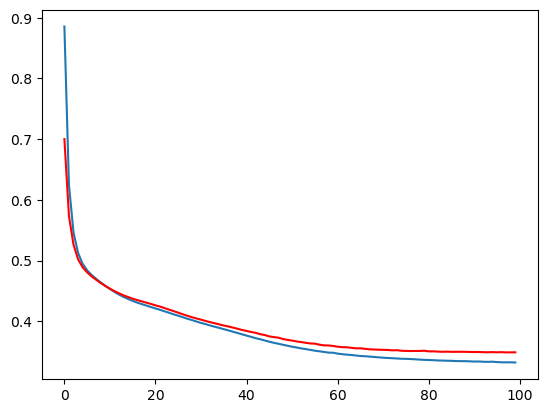

In [35]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'],'r')

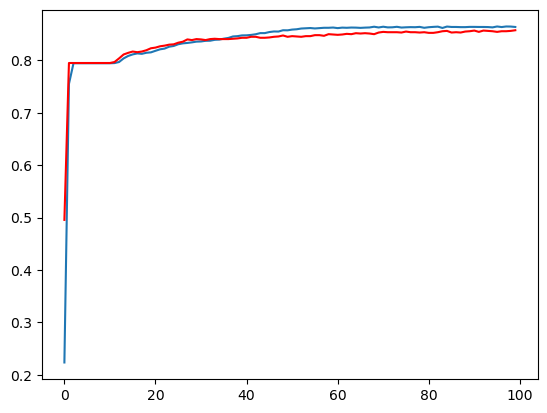

In [36]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'],'r')